# 07 — Baseline Comparison with Logistic Regression and Random Forest

## Objective

This notebook compares two conventional machine learning classifiers using the same whole-gland T2W radiomic features used in the XGBoost experiment.

The workflow includes:

1. Loading radiomic features, clinical labels, and the grouped_v2 patient-disjoint split
2. Validating case identifiers, target labels, and radiomic feature values
3. Preparing the training, validation, and test subsets
4. Training Logistic Regression and Random Forest candidates
5. Selecting hyperparameters and decision thresholds on validation data
6. Evaluating frozen models on test data
7. Saving metrics, visualizations, predictions, and model artifacts

The binary target is `case_csPCa`. This is an exploratory retrospective comparison, not a clinical risk prediction study.

## 1. Environment and Paths

The project structure and source files follow notebook 06. The existing patient-level split is reused without generating new random partitions.

In [1]:
from pathlib import Path
import json
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    PrecisionRecallDisplay,
    recall_score,
    roc_auc_score,
    roc_curve,
    RocCurveDisplay,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "notebooks" else cwd
RANDOM_STATE = 42

features_path = (
    PROJECT_ROOT
    / "src" / "data" / "features"
    / "whole_gland_t2w_radiomics_grouped_v2.csv"
)
clinical_path = (
    PROJECT_ROOT
    / "src" / "data" / "raw" / "picai_labels"
    / "clinical_information" / "marksheet.csv"
)
splits_path = (
    PROJECT_ROOT
    / "src" / "data" / "processed"
    / "splits" / "patient_splits_grouped_v2.csv"
)
results_dir = (
    PROJECT_ROOT
    / "results" / "baseline_comparison_grouped_v2"
)

print("Project root:", PROJECT_ROOT)
print("Radiomics:", features_path)
print("Clinical:", clinical_path)
print("Splits:", splits_path)
print("Results:", results_dir)

Project root: C:\Users\Luiz Trindade\Documents\penguin-adventure\TCC_II
Radiomics: C:\Users\Luiz Trindade\Documents\penguin-adventure\TCC_II\src\data\features\whole_gland_t2w_radiomics_grouped_v2.csv
Clinical: C:\Users\Luiz Trindade\Documents\penguin-adventure\TCC_II\src\data\raw\picai_labels\clinical_information\marksheet.csv
Splits: C:\Users\Luiz Trindade\Documents\penguin-adventure\TCC_II\src\data\processed\splits\patient_splits_grouped_v2.csv
Results: C:\Users\Luiz Trindade\Documents\penguin-adventure\TCC_II\results\baseline_comparison_grouped_v2


## 2. Loading the Classification Data

The radiomic features, PI-CAI clinical marksheet, and patient-level split are loaded separately, preserving `patient_id` and `study_id` as strings.

In [2]:
for required_path in [
    features_path,
    clinical_path,
    splits_path,
]:
    if not required_path.is_file():
        raise FileNotFoundError(
            f"Required dataset file not found: {required_path}"
        )

identifier_types = {
    "patient_id": str,
    "study_id": str,
}

radiomics_dataframe = pd.read_csv(
    features_path,
    dtype=identifier_types,
)
clinical_dataframe = pd.read_csv(
    clinical_path,
    dtype=identifier_types,
)
splits_dataframe = pd.read_csv(
    splits_path,
    dtype=identifier_types,
)

print("Radiomics:", radiomics_dataframe.shape)
print("Clinical:", clinical_dataframe.shape)
print("Splits:", splits_dataframe.shape)
print("Radiomics columns:", radiomics_dataframe.columns[:6].tolist())
print("Split columns:", splits_dataframe.columns.tolist())

Radiomics: (1500, 109)
Clinical: (1500, 14)
Splits: (1500, 3)
Radiomics columns: ['patient_id', 'study_id', 'original_shape_Elongation', 'original_shape_Flatness', 'original_shape_LeastAxisLength', 'original_shape_MajorAxisLength']
Split columns: ['patient_id', 'study_id', 'split']


### 2.1 Case Identifier and Label Validation

A case is identified by the combination of patient and study identifiers. The clinical label is loaded from the marksheet, while the partition is loaded from the saved split file.

In [3]:
id_columns = ["patient_id", "study_id"]

for source_name, dataframe in [
    ("Radiomics", radiomics_dataframe),
    ("Clinical", clinical_dataframe),
    ("Splits", splits_dataframe),
]:
    missing_columns = set(id_columns) - set(dataframe.columns)
    if missing_columns:
        raise ValueError(
            f"{source_name} is missing identifiers: {missing_columns}"
        )
    if dataframe.duplicated(id_columns).any():
        raise ValueError(
            f"{source_name} contains duplicate patient-study pairs"
        )

if "case_csPCa" not in clinical_dataframe.columns:
    raise ValueError("Clinical marksheet is missing case_csPCa")
if "split" not in splits_dataframe.columns:
    raise ValueError("Patient split file is missing the split column")

classification_dataframe = radiomics_dataframe.merge(
    clinical_dataframe[id_columns + ["case_csPCa"]],
    on=id_columns,
    how="left",
    validate="one_to_one",
    indicator="clinical_match",
)
classification_dataframe = classification_dataframe.merge(
    splits_dataframe[id_columns + ["split"]],
    on=id_columns,
    how="left",
    validate="one_to_one",
    indicator="split_match",
)

if not classification_dataframe["clinical_match"].eq("both").all():
    raise ValueError("Some radiomic cases have no clinical label")
if not classification_dataframe["split_match"].eq("both").all():
    raise ValueError("Some radiomic cases have no saved partition")

classification_dataframe = classification_dataframe.drop(
    columns=["clinical_match", "split_match"]
)

if len(classification_dataframe) != 1500:
    raise ValueError(
        f"Expected 1500 cases, found {len(classification_dataframe)}"
    )

label_values = (
    classification_dataframe["case_csPCa"]
    .astype(str).str.strip().str.upper()
)
label_mapping = {
    "YES": 1,
    "NO": 0,
    "1": 1,
    "0": 0,
    "TRUE": 1,
    "FALSE": 0,
}
classification_dataframe["target"] = label_values.map(label_mapping)
if classification_dataframe["target"].isna().any():
    raise ValueError(
        "Unexpected case_csPCa labels: "
        + str(label_values[classification_dataframe["target"].isna()].unique())
    )
classification_dataframe["target"] = (
    classification_dataframe["target"].astype(int)
)

classification_dataframe["split"] = (
    classification_dataframe["split"]
    .astype(str).str.strip().str.lower()
    .replace({"validation": "val"})
)
if set(classification_dataframe["split"]) != {"train", "val", "test"}:
    raise ValueError(
        "Expected train, val, and test partitions; found "
        + str(classification_dataframe["split"].unique())
    )

print("Total cases:", len(classification_dataframe))
display(pd.crosstab(
    classification_dataframe["split"],
    classification_dataframe["target"],
))
# Patient-level separation is required, not only case-level separation.
patient_partitions = classification_dataframe.groupby("patient_id")["split"].nunique()
shared_patients = int((patient_partitions > 1).sum())
print("Patients in multiple partitions:", shared_patients)
if shared_patients:
    raise ValueError("Patient leakage detected between train, val, and test")


Total cases: 1500


C:\Users\Luiz Trindade\AppData\Local\Temp\ipykernel_13992\1272372380.py:23: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  classification_dataframe = radiomics_dataframe.merge(
C:\Users\Luiz Trindade\AppData\Local\Temp\ipykernel_13992\1272372380.py:23: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  classification_dataframe = radiomics_dataframe.merge(
C:\Users\Luiz Trindade\AppData\Local\Temp\ipykernel_13992\1272372380.py:30: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` 

target,0,1
split,,
test,161,64
train,752,297
val,162,64


Patients in multiple partitions: 0


### 2.2 Radiomic Feature Validation

Only radiomic columns are used as predictors. Clinical variables, identifiers, and split labels are excluded. The 107 features must have finite numerical values or values suitable for training-only imputation.

In [4]:
feature_columns = [
    column
    for column in radiomics_dataframe.columns
    if column not in id_columns
]

if len(feature_columns) != 107:
    raise ValueError(
        f"Expected 107 radiomic features, found {len(feature_columns)}"
    )

classification_dataframe[feature_columns] = (
    classification_dataframe[feature_columns]
    .apply(pd.to_numeric, errors="coerce")
    .replace([np.inf, -np.inf], np.nan)
)

if classification_dataframe[feature_columns].isna().all(axis=0).any():
    raise ValueError("At least one radiomic feature is entirely missing")

print("Radiomic features:", len(feature_columns))
print(
    "Missing feature values:",
    int(classification_dataframe[feature_columns].isna().sum().sum()),
)
print("Target distribution:")
display(classification_dataframe["target"].value_counts().sort_index())

Radiomic features: 107
Missing feature values: 0
Target distribution:


target
0    1075
1     425
Name: count, dtype: int64

## 3. Train, Validation, and Test Subsets

The same 70% / 15% / 15% patient-level partition as the previous notebooks is retained. Model fitting occurs only on training cases; validation cases are used for configuration and threshold selection.

In [5]:
expected_distribution = {
    "train": (752, 297),
    "val": (162, 64),
    "test": (161, 64),
}

X = {}
y = {}
case_ids = {}

for split_name, (expected_negative, expected_positive) in (
    expected_distribution.items()
):
    subset = classification_dataframe.loc[
        classification_dataframe["split"] == split_name
    ].copy()
    X[split_name] = subset[feature_columns]
    y[split_name] = subset["target"].to_numpy()
    case_ids[split_name] = subset[id_columns].reset_index(drop=True)

    observed = (
        int(np.sum(y[split_name] == 0)),
        int(np.sum(y[split_name] == 1)),
    )
    if observed != (expected_negative, expected_positive):
        raise ValueError(
            f"Unexpected {split_name} class distribution: {observed}"
        )
    print(
        split_name,
        "cases:", len(subset),
        "features:", X[split_name].shape[1],
        "class counts:", observed,
    )

assert set(map(tuple, case_ids["train"].to_numpy())).isdisjoint(
    set(map(tuple, case_ids["val"].to_numpy()))
)
assert set(map(tuple, case_ids["train"].to_numpy())).isdisjoint(
    set(map(tuple, case_ids["test"].to_numpy()))
)
assert set(map(tuple, case_ids["val"].to_numpy())).isdisjoint(
    set(map(tuple, case_ids["test"].to_numpy())))

print("Case-level partitions validated")

train cases: 1049 features: 107 class counts: (752, 297)
val cases: 226 features: 107 class counts: (162, 64)
test cases: 225 features: 107 class counts: (161, 64)
Case-level partitions validated


## 4. Baseline Model Configuration

Logistic Regression uses median imputation and standardization. Random Forest uses median imputation without standardization. Both preprocessing pipelines are fitted exclusively on training data. The candidates are selected by validation ROC-AUC.

In [6]:
logistic_candidates = [
    (
        f"C={regularization}",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("classifier", LogisticRegression(
                C=regularization,
                class_weight="balanced",
                max_iter=3000,
                solver="liblinear",
                random_state=RANDOM_STATE,
            )),
        ]),
    )
    for regularization in [0.01, 0.1, 1.0, 10.0]
]

forest_candidates = [
    (
        f"trees={trees}, depth={depth}, leaf={leaf}",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("classifier", RandomForestClassifier(
                n_estimators=trees,
                max_depth=depth,
                min_samples_leaf=leaf,
                class_weight="balanced",
                n_jobs=-1,
                random_state=RANDOM_STATE,
            )),
        ]),
    )
    for trees in [150, 300]
    for depth in [5, 10, None]
    for leaf in [2, 5]
]

model_candidates = {
    "Logistic Regression": logistic_candidates,
    "Random Forest": forest_candidates,
}

for model_name, candidates in model_candidates.items():
    print(model_name, "configurations:", len(candidates))

Logistic Regression configurations: 4
Random Forest configurations: 12


## 5. Model Training and Validation

Every candidate is fitted only on training cases and scored on validation cases. Candidate selection does not inspect test cases.

In [7]:
selection_records = []
selected_models = {}

for model_name, candidates in model_candidates.items():
    best_auc = float("-inf")

    for configuration, candidate in candidates:
        start_time = time.perf_counter()
        candidate.fit(X["train"], y["train"])
        training_seconds = time.perf_counter() - start_time

        validation_scores = candidate.predict_proba(X["val"])[:, 1]
        validation_auc = roc_auc_score(
            y["val"], validation_scores
        )
        selection_records.append({
            "model": model_name,
            "configuration": configuration,
            "validation_roc_auc": validation_auc,
            "training_seconds": training_seconds,
        })
        if validation_auc > best_auc:
            best_auc = validation_auc
            selected_models[model_name] = {
                "model": candidate,
                "configuration": configuration,
                "validation_roc_auc": validation_auc,
                "training_seconds": training_seconds,
            }

selection_dataframe = pd.DataFrame(selection_records).sort_values(
    by=["model", "validation_roc_auc"],
    ascending=[True, False],
)
display(selection_dataframe)

for model_name, result in selected_models.items():
    print(
        model_name,
        "selected:", result["configuration"],
        "validation ROC-AUC:",
        round(result["validation_roc_auc"], 4),
    )

,model,configuration,validation_roc_auc,training_seconds
1,Logistic Regression,C=0.1,0.650849,0.037758
0,Logistic Regression,C=0.01,0.646219,0.087929
2,Logistic Regression,C=1.0,0.624711,0.051016
3,Logistic Regression,C=10.0,0.601080,0.092767
4,Random Forest,"trees=150, depth=5, leaf=2",0.669560,0.338037
5,Random Forest,"trees=150, depth=5, leaf=5",0.663966,0.339307
13,Random Forest,"trees=300, depth=10, leaf=5",0.663580,0.642093
8,Random Forest,"trees=150, depth=None, leaf=2",0.663098,0.368766
7,Random Forest,"trees=150, depth=10, leaf=5",0.661651,0.343240
10,Random Forest,"trees=300, depth=5, leaf=2",0.661651,0.660425


Logistic Regression selected: C=0.1 validation ROC-AUC: 0.6508
Random Forest selected: trees=150, depth=5, leaf=2 validation ROC-AUC: 0.6696


### 5.1 Validation-Based Decision Threshold

The Youden index determines one decision threshold per selected classifier from the validation subset. These thresholds remain fixed when evaluating test cases.

In [8]:
def select_youden_threshold(targets, scores):
    false_positive_rate, true_positive_rate, thresholds = roc_curve(
        targets, scores
    )
    finite_thresholds = np.isfinite(thresholds)
    youden_values = (
        true_positive_rate[finite_thresholds]
        - false_positive_rate[finite_thresholds]
    )
    return float(
        thresholds[finite_thresholds][np.argmax(youden_values)]
    )

for model_name, result in selected_models.items():
    validation_scores = result["model"].predict_proba(
        X["val"]
    )[:, 1]
    result["threshold"] = select_youden_threshold(
        y["val"], validation_scores
    )
    print(
        model_name,
        "validation threshold:",
        round(result["threshold"], 6),
    )

Logistic Regression validation threshold: 0.443175
Random Forest validation threshold: 0.563622


## 6. Final Test Evaluation

Execute this stage only after selecting all configurations and thresholds using training and validation data. Results must not be used for further model tuning.

In [9]:
def calculate_classification_metrics(targets, scores, threshold):
    predictions = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        targets, predictions, labels=[0, 1]
    ).ravel()

    return {
        "roc_auc": roc_auc_score(targets, scores),
        "pr_auc": average_precision_score(targets, scores),
        "sensitivity": recall_score(
            targets, predictions, zero_division=0
        ),
        "specificity": float(tn / (tn + fp)),
        "precision": precision_score(
            targets, predictions, zero_division=0
        ),
        "f1_score": f1_score(targets, predictions, zero_division=0),
        "accuracy": accuracy_score(targets, predictions),
        "balanced_accuracy": balanced_accuracy_score(
            targets, predictions
        ),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    }

metrics_records = []
prediction_records = []

for model_name, result in selected_models.items():
    test_scores = result["model"].predict_proba(X["test"])[:, 1]
    metrics = calculate_classification_metrics(
        y["test"], test_scores, result["threshold"]
    )
    metrics_records.append({
        "model": model_name,
        "configuration": result["configuration"],
        "validation_roc_auc": result["validation_roc_auc"],
        "threshold": result["threshold"],
        **metrics,
    })

    case_predictions = case_ids["test"].copy()
    case_predictions["model"] = model_name
    case_predictions["target"] = y["test"]
    case_predictions["score"] = test_scores
    case_predictions["prediction"] = (
        test_scores >= result["threshold"]
    ).astype(int)
    prediction_records.append(case_predictions)

metrics_dataframe = pd.DataFrame(metrics_records)
predictions_dataframe = pd.concat(
    prediction_records, ignore_index=True
)

display(metrics_dataframe.round(4))

,model,configuration,validation_roc_auc,threshold,roc_auc,pr_auc,sensitivity,specificity,precision,f1_score,accuracy,balanced_accuracy,tn,fp,fn,tp
0,Logistic Regression,C=0.1,0.6508,0.4432,0.6852,0.4440,0.7812,0.5093,0.3876,0.5181,0.5867,0.6453,82,79,14,50
1,Random Forest,"trees=150, depth=5, leaf=2",0.6696,0.5636,0.6629,0.4137,0.5000,0.7081,0.4051,0.4476,0.6489,0.6040,114,47,32,32


### 6.1 Test ROC Curves

ROC curves visualize discrimination independently of the selected decision thresholds.

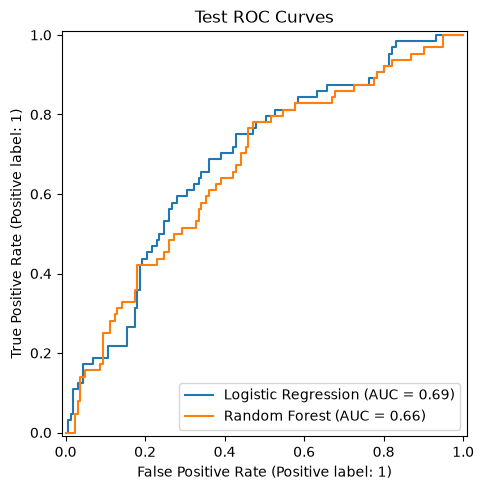

In [10]:
fig, ax = plt.subplots(figsize=(7, 5))

for model_name, result in selected_models.items():
    test_scores = result["model"].predict_proba(X["test"])[:, 1]
    RocCurveDisplay.from_predictions(
        y["test"], test_scores,
        name=model_name, ax=ax,
    )

ax.set_title("Test ROC Curves")
fig.tight_layout()
results_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(
    results_dir / "test_roc_curves.png", dpi=160
)
plt.show()

### 6.2 Test Precision–Recall Curves

Precision–recall curves complement ROC-AUC when classes are imbalanced.

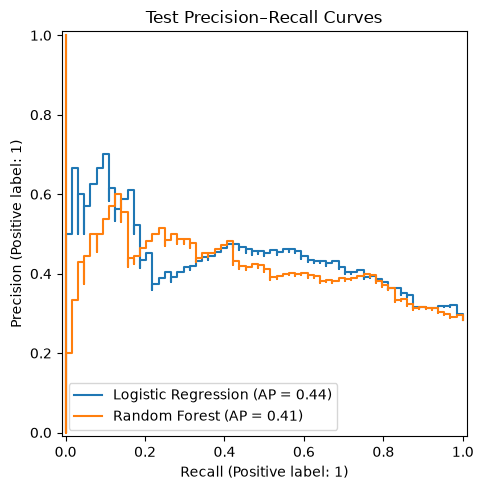

In [11]:
fig, ax = plt.subplots(figsize=(7, 5))

for model_name, result in selected_models.items():
    test_scores = result["model"].predict_proba(X["test"])[:, 1]
    PrecisionRecallDisplay.from_predictions(
        y["test"], test_scores,
        name=model_name, ax=ax,
    )

ax.set_title("Test Precision–Recall Curves")
fig.tight_layout()
results_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(
    results_dir / "test_pr_curves.png", dpi=160
)
plt.show()

### 6.3 Confusion Matrices

Confusion matrices display true negatives, false positives, false negatives, and true positives for the validation-selected thresholds.

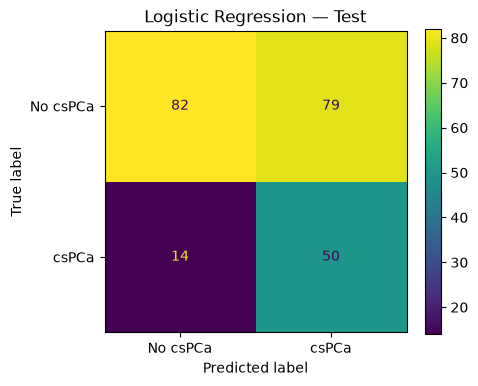

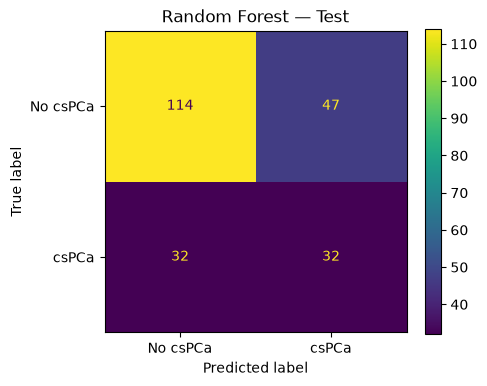

In [12]:
for model_name, result in selected_models.items():
    test_scores = result["model"].predict_proba(X["test"])[:, 1]
    test_predictions = (
        test_scores >= result["threshold"]
    ).astype(int)

    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_predictions(
        y["test"], test_predictions,
        labels=[0, 1],
        display_labels=["No csPCa", "csPCa"],
        ax=ax,
    )
    ax.set_title(f"{model_name} — Test")
    fig.tight_layout()
    results_dir.mkdir(parents=True, exist_ok=True)
    filename = model_name.lower().replace(" ", "_")
    fig.savefig(
        results_dir / f"{filename}_confusion_matrix.png",
        dpi=160,
    )
    plt.show()

## 7. Saving Experimental Results

The model configurations, selection history, metrics, test predictions, figures, and fitted pipelines are saved for reproducibility and thesis reporting.

In [13]:
results_dir.mkdir(parents=True, exist_ok=True)

selection_dataframe.to_csv(
    results_dir / "validation_model_selection.csv",
    index=False,
)
metrics_dataframe.to_csv(
    results_dir / "test_metrics.csv",
    index=False,
)
predictions_dataframe.to_csv(
    results_dir / "test_predictions.csv",
    index=False,
)

for model_name, result in selected_models.items():
    model_filename = model_name.lower().replace(" ", "_")
    joblib.dump(
        result["model"],
        results_dir / f"{model_filename}.joblib",
    )

experiment_metadata = {
    "random_state": RANDOM_STATE,
    "features_path": str(features_path),
    "clinical_path": str(clinical_path),
    "splits_path": str(splits_path),
    "feature_columns": feature_columns,
    "candidate_selection_metric": "validation_roc_auc",
    "threshold_selection": "validation_youden_index",
    "models": {
        model_name: {
            "configuration": result["configuration"],
            "validation_roc_auc": result["validation_roc_auc"],
            "threshold": result["threshold"],
            "training_seconds": result["training_seconds"],
        }
        for model_name, result in selected_models.items()
    },
}

with (results_dir / "experiment_config.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(experiment_metadata, file, indent=2)

print("Results saved to:", results_dir)

Results saved to: C:\Users\Luiz Trindade\Documents\penguin-adventure\TCC_II\results\baseline_comparison_grouped_v2


## 8. Experimental Comparison Summary

The table compares the newly trained Logistic Regression and Random Forest models
with the saved **grouped_v2 XGBoost** evaluation from notebook 06.
All models use the same named feature table and patient-grouped split.
Metrics for XGBoost are loaded from its saved evaluation rather than being hardcoded.


In [14]:
# Read the confirmed grouped_v2 XGBoost result instead of hardcoding historical metrics.
xgboost_metrics_path = (
    PROJECT_ROOT / "results" / "classification" / "grouped_v2_xgboost"
    / "test_metrics_grouped_v2.csv"
)
if not xgboost_metrics_path.is_file():
    raise FileNotFoundError(
        f"Run notebook 06 grouped_v2 first: {xgboost_metrics_path}"
    )
xgb_metrics = pd.read_csv(xgboost_metrics_path)
xgb_metadata_path = xgboost_metrics_path.parent / "metadata_grouped_v2.json"
if not xgb_metadata_path.is_file():
    raise FileNotFoundError(f"Missing XGBoost provenance: {xgb_metadata_path}")
with xgb_metadata_path.open(encoding="utf-8") as f:
    xgb_metadata = json.load(f)
if Path(xgb_metadata["input_features"]).name != features_path.name or Path(xgb_metadata["input_splits"]).name != splits_path.name:
    raise ValueError("XGBoost metrics provenance does not match grouped_v2 inputs")
if len(xgb_metrics) != 1:
    raise ValueError("Expected exactly one XGBoost metrics row")

xgboost_reference = xgb_metrics.rename(columns={
    "average_precision": "pr_auc",
}).copy()
xgboost_reference.insert(0, "model", "XGBoost (grouped_v2)")

comparison_columns = [
    "model", "roc_auc", "pr_auc", "sensitivity",
    "specificity", "precision", "f1_score",
    "accuracy", "balanced_accuracy",
]
comparison_dataframe = pd.concat([
    metrics_dataframe[comparison_columns],
    xgboost_reference[comparison_columns],
], ignore_index=True)

display(comparison_dataframe.round(4))
comparison_dataframe.to_csv(
    results_dir / "model_comparison.csv", index=False
)

,model,roc_auc,pr_auc,sensitivity,specificity,precision,f1_score,accuracy,balanced_accuracy
0,Logistic Regression,0.6852,0.4440,0.7812,0.5093,0.3876,0.5181,0.5867,0.6453
1,Random Forest,0.6629,0.4137,0.5000,0.7081,0.4051,0.4476,0.6489,0.6040
2,XGBoost (grouped_v2),0.6732,0.4316,0.4531,0.7516,0.4203,0.4361,0.6667,0.6023


## 9. Interpretation and Limitations

- Models are compared at the **case level**, not at the lesion level.
- Radiomic features originate from the same predicted whole-gland masks and T2W images.
- Candidate models and thresholds are selected using validation data only.
- The XGBoost results are read from notebook 06 grouped_v2, with input filenames verified from saved metadata.
- Because the XGBoost test results were already known before designing this additional experiment, the comparison is **retrospective and exploratory**. It does not constitute an independent confirmation of superiority.
- `predict_proba` outputs are not calibrated estimates of clinical risk without a separate calibration assessment.
- This notebook does not implement cross-validation or external clinical validation.